In [ ]:
#import the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


DATE_COL  = "date"
LEVEL_COL = "water_level_mean"

DATA_PATH  = "../data/processed/kaub_water_weather_daily.csv"
HORIZON    = 7       # forecast 7 days ahead
TEST_YEARS = 3       # hold out the most recent 3 years

pd.set_option("display.width", 120)


date                 datetime64[us]
water_level_mean            float64
water_level_min             float64
water_level_max             float64
temperature_mean            float64
humidity_mean               float64
precipitation_sum           float64
rain_sum                    float64
snowfall_sum                float64
pressure_mean               float64
wind_speed_mean             float64
dtype: object
        date  water_level_mean  water_level_min  water_level_max  temperature_mean  humidity_mean  precipitation_sum  \
0 2000-01-01        438.989130           420.75           458.25          3.286957      97.434783                1.7   
1 2000-01-02        401.260417           385.25           419.00          3.979167      96.291667                0.0   
2 2000-01-03        367.989583           359.25           383.50          2.350000      94.458333                0.0   

   rain_sum  snowfall_sum  pressure_mean  wind_speed_mean  
0       1.7           0.0    1025.256522         

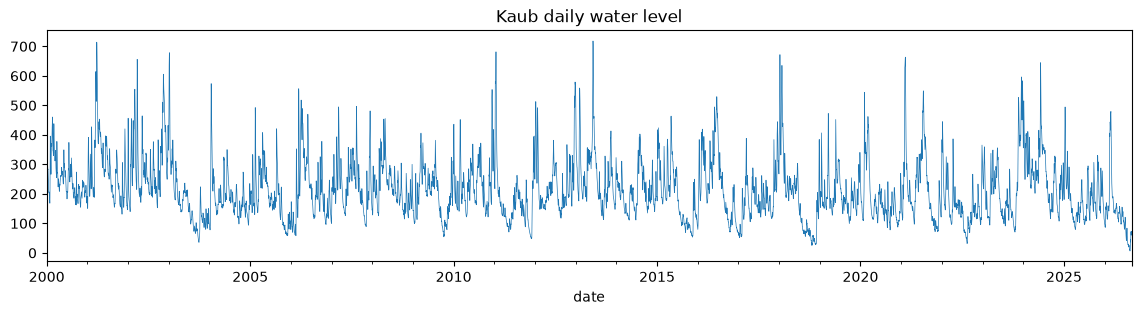

In [ ]:
#Read data and plot kaub daily water level
df = pd.read_csv(DATA_PATH, parse_dates=["date"])
print(df.dtypes)
print(df.head(3))# sanity-check for two constants

s = (df[[DATE_COL, LEVEL_COL]]
     .dropna(subset=[DATE_COL])
     .sort_values(DATE_COL)
     .drop_duplicates(subset=[DATE_COL], keep="last")
     .set_index(DATE_COL)[LEVEL_COL]
     .asfreq("D"))                            # explicit NaN for absent days

print(f"{s.index.min().date()} → {s.index.max().date()}  ({len(s)} days)")
print("missing days:", int(s.isna().sum()))
s.plot(figsize=(14, 3), lw=0.5, title="Kaub daily water level")
plt.show()


In [15]:
#water level condition
levels = s.dropna()

low_threshold = 77
high_threshold = levels.quantile(0.90)

counts = pd.Series({
    "Low water": (levels <= low_threshold).sum(),
    "Normal water": (
        (levels > low_threshold) & (levels < high_threshold)
    ).sum(),
    "High water": (levels >= high_threshold).sum()
})

summary = counts.rename("Number of days").to_frame()
summary["Percentage (%)"] = (counts / len(levels) * 100).round(2)

print(f"Low water: ≤ {low_threshold} cm")
print(f"Normal water: > {low_threshold} and < {high_threshold:.1f} cm")
print(f"High water: ≥ {high_threshold:.1f} cm")

display(summary)

Low water: ≤ 77 cm
Normal water: > 77 and < 347.0 cm
High water: ≥ 347.0 cm


,Number of days,Percentage (%)
Low water,400,4.11
Normal water,8366,85.88
High water,975,10.01


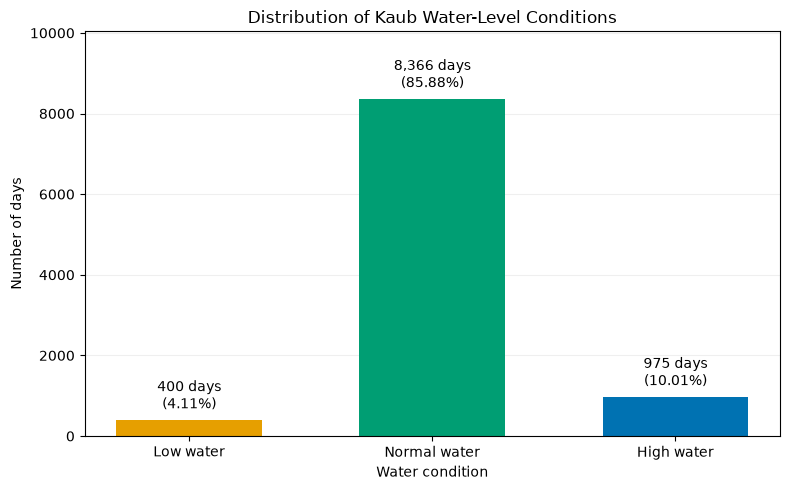

In [14]:
# Plot for water level condition distribution

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    summary.index,
    summary["Number of days"],
    color=["#E69F00", "#009E73", "#0072B2"],
    width=0.6
)

# Display counts and percentages above each bar
labels = [
    f"{days:,} days\n({pct:.2f}%)"
    for days, pct in zip(
        summary["Number of days"],
        summary["Percentage (%)"]
    )
]

ax.bar_label(bars, labels=labels, padding=5)

ax.set(
    title="Distribution of Kaub Water-Level Conditions",
    xlabel="Water condition",
    ylabel="Number of days",
    ylim=(0, summary["Number of days"].max() * 1.2)
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [ ]:
# Create lag features (past water levels) and the 7-day-ahead target
H    = HORIZON
LAGS = [0, 1, 2, 3, 4, 5, 6, 7, 14, 21, 28]

data = pd.DataFrame(index=s.index)
for L in LAGS:
    data[f"lag_{L}"] = s.shift(L)            # all ≤ day t
data["target"] = s.shift(-H)                 # day t+7

FEATURES = [f"lag_{L}" for L in LAGS]
data.head(35)

In [ ]:
# Check that lag_0 is today's level and target is the level 7 days later
i = 400
row = data.iloc[i]
assert row["lag_0"] == s.iloc[i]                 # feature is today
assert row["target"] == s.iloc[i + H]            # target is today + 7
print(f"on {data.index[i].date()}: today={row['lag_0']}, target(+7d)={row['target']}")

In [ ]:
# Split by time: last 3 years = test, with a 7-day gap so no target overlaps the test period
split_date = data.index.max() - pd.DateOffset(years=TEST_YEARS)

train = data.loc[: split_date - pd.Timedelta(days=H)].dropna()
test  = data.loc[split_date + pd.Timedelta(days=1):].dropna()

X_train, y_train = train[FEATURES], train["target"]
X_test,  y_test  = test[FEATURES],  test["target"]

print(f"train: {train.index.min().date()} → {train.index.max().date()}  n={len(train)}")
print(f"test : {test.index.min().date()} → {test.index.max().date()}  n={len(test)}")
assert train.index.max() + pd.Timedelta(days=H) < test.index.min(), "embargo violated"

In [ ]:
# Persistence baseline: the level in 7 days = today's level (training data)
pred_persist = X_train["lag_0"].rename("persistence")
print(pred_persist)

In [ ]:
# Linear autoregressive (AR) model: predict the level in 7 days from past levels
from sklearn.linear_model import LinearRegression

ar = LinearRegression()
ar.fit(X_train, y_train)

pred_ar = pd.Series(ar.predict(X_train), index=X_train.index, name="linear_ar")

print(pd.Series(ar.coef_, index=FEATURES).round(3))
print("intercept:", round(ar.intercept_, 2))

In [ ]:
# Compare persistence and linear AR on the training data (MAE, RMSE, bias, skill)
def evaluate(y_true, y_pred, name):

    err = y_true - y_pred

    return pd.Series({
        "MAE": err.abs().mean(),
        "RMSE": np.sqrt((err ** 2).mean()),
        "bias": err.mean(),
    }, name=name)


results = pd.concat([

    evaluate(y_train, pred_persist, "persistence"),

    evaluate(y_train, pred_ar, "linear_ar"),

], axis=1).T


rmse_p = results.loc["persistence", "RMSE"]
rmse_a = results.loc["linear_ar", "RMSE"]

results["skill_vs_persistence"] = [
    0.0,
    1 - (rmse_a ** 2) / (rmse_p ** 2)
]

print(f"Horizon: {H} days | train n = {len(y_train)}")

print(results.round(3))

In [ ]:
# Plot persistence and linear AR predictions over the training period
fig, axes = plt.subplots(2, 1, figsize=(15, 9))

ax = axes[0]
#ax.plot(y_test.index, y_test,      lw=1.0, color="black", label="actual")
ax.plot(pred_persist.index, pred_persist, lw=0.8, alpha=.75, label="persistence")
ax.plot(pred_ar.index, pred_ar,          lw=0.8, alpha=.85, label="linear AR")
ax.set_title(f"Kaub water level pattern")
ax.set_ylabel("level (cm)"); ax.legend(); ax.grid(alpha=.3)


#plt.tight_layout(); 
plt.show()

In [ ]:
# Error distribution and error vs actual level for both models (training data)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for p, n in [(pred_persist, "persistence"), (pred_ar, "linear AR")]:
    ax[0].hist(y_train - p, bins=60, alpha=.55, label=n)
    ax[1].scatter(y_train, (y_train - p).abs(), s=3, alpha=.25, label=n)
ax[0].set_title("forecast error (cm)"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].set_xlabel("actual level (cm)"); ax[1].set_ylabel("|error| (cm)")
ax[1].set_title("error vs level"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()